# ArcFace + SVM on Yale Face Database



In [1]:
# Install InsightFace 
!pip install -q insightface

In [2]:
# Imports, load dataset, and select 10 subjects
import os, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

DATASET_PATH = "/kaggle/input/datasets/olgabelitskaya/yale-face-database"
files = sorted(f for f in os.listdir(DATASET_PATH) if f.startswith("subject") and os.path.isfile(os.path.join(DATASET_PATH, f)))

df = pd.DataFrame([{
    "image_path": os.path.join(DATASET_PATH, f),
    "image_name": f,
    "identity": f.split(".")[0],
    "variation": f.split(".")[1].lower()
} for f in files])
selected_identities = sorted(df.identity.unique())[:10]
project_df = df[df.identity.isin(selected_identities)].reset_index(drop=True)

print(f"Images: {len(project_df)} | Subjects: {project_df.identity.nunique()} | Variations: {project_df.variation.nunique()}")
print(project_df.groupby("identity").size())

Images: 110 | Subjects: 10 | Variations: 11
identity
subject01    11
subject02    11
subject03    11
subject04    11
subject05    11
subject06    11
subject07    11
subject08    11
subject09    11
subject10    11
dtype: int64


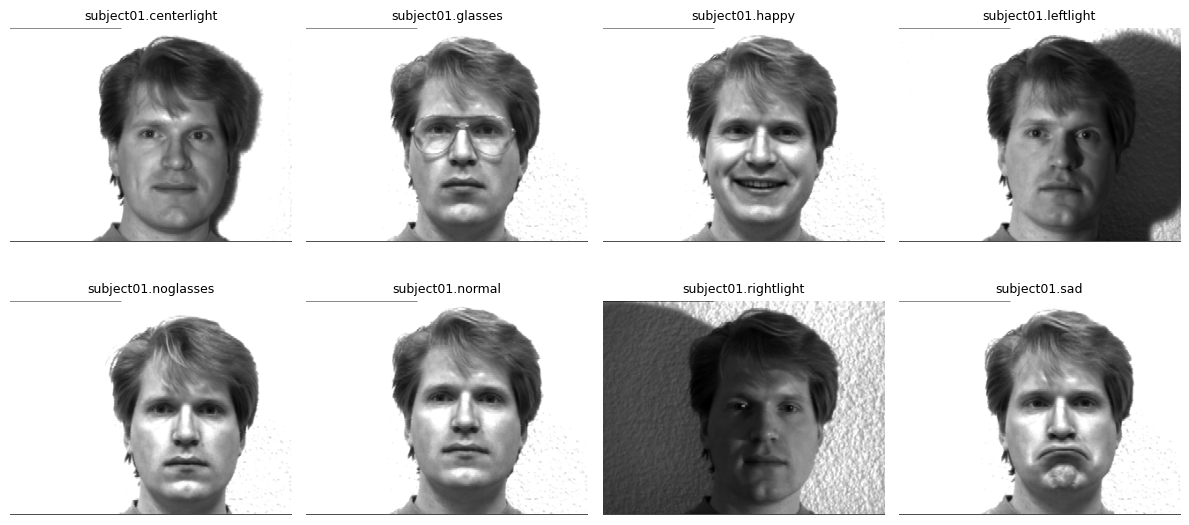

In [3]:
# visualize 8 sample images
sample = project_df.head(8)
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, row in zip(axes.flat, sample.itertuples()):
    ax.imshow(Image.open(row.image_path).convert("RGB"))
    ax.set_title(row.image_name, fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.show()

In [4]:
# Load pretrained ArcFace (InsightFace buffalo_l)
from insightface.app import FaceAnalysis

app = FaceAnalysis(name="buffalo_l", providers=["CPUExecutionProvider"])
app.prepare(ctx_id=-1, det_size=(640, 640))
print("ArcFace model ready")

download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:02<00:00, 109655.77KB/s]


ArcFace model ready


In [5]:
# Extract embeddings and L2-normalize
embeddings, labels, variations, image_names, no_face = [], [], [], [], []

for row in tqdm(project_df.itertuples(), total=len(project_df)):
    image = cv2.imread(row.image_path)
    faces = app.get(image)
    if not faces:
        no_face.append(row.image_name)
        continue
    face = max(faces, key=lambda f: (f.bbox[2]-f.bbox[0])*(f.bbox[3]-f.bbox[1]))
    embeddings.append(face.embedding)
    labels.append(row.identity)
    variations.append(row.variation)
    image_names.append(row.image_name)

embeddings = np.asarray(embeddings)
from sklearn.preprocessing import normalize
X = normalize(embeddings, norm="l2")
y = np.asarray(labels)
variations = np.asarray(variations)
image_names = np.asarray(image_names)
print(f"Embeddings: {X.shape} | Missed faces: {len(no_face)}")

  0%|          | 0/110 [00:00<?, ?it/s]

Embeddings: (110, 512) | Missed faces: 0


In [6]:
# 3-fold stratified CV: linear SVM
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
oof_pred = np.empty(len(y), dtype=object)
fold_results = []

for fold, (train_idx, test_idx) in enumerate(cv.split(X, y), 1):
    model = SVC(kernel="linear", C=1.0)
    model.fit(X[train_idx], y[train_idx])
    pred = model.predict(X[test_idx])
    oof_pred[test_idx] = pred
    fold_results.append({
        "Fold": fold,
        "Accuracy": accuracy_score(y[test_idx], pred),
        "Precision": precision_score(y[test_idx], pred, average="macro", zero_division=0),
        "Recall": recall_score(y[test_idx], pred, average="macro", zero_division=0),
        "F1": f1_score(y[test_idx], pred, average="macro", zero_division=0)
    })

fold_results_df = pd.DataFrame(fold_results)
print(fold_results_df.to_string(index=False))
print("\nMean metrics:")
print(fold_results_df.mean(numeric_only=True).round(4))

 Fold  Accuracy  Precision  Recall  F1
    1       1.0        1.0     1.0 1.0
    2       1.0        1.0     1.0 1.0
    3       1.0        1.0     1.0 1.0

Mean metrics:
Fold         2.0
Accuracy     1.0
Precision    1.0
Recall       1.0
F1           1.0
dtype: float64


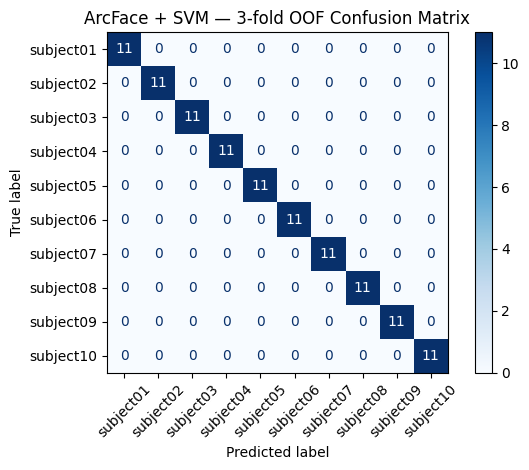

              precision    recall  f1-score   support

   subject01     1.0000    1.0000    1.0000        11
   subject02     1.0000    1.0000    1.0000        11
   subject03     1.0000    1.0000    1.0000        11
   subject04     1.0000    1.0000    1.0000        11
   subject05     1.0000    1.0000    1.0000        11
   subject06     1.0000    1.0000    1.0000        11
   subject07     1.0000    1.0000    1.0000        11
   subject08     1.0000    1.0000    1.0000        11
   subject09     1.0000    1.0000    1.0000        11
   subject10     1.0000    1.0000    1.0000        11

    accuracy                         1.0000       110
   macro avg     1.0000    1.0000    1.0000       110
weighted avg     1.0000    1.0000    1.0000       110

OOF accuracy: 1.0000
  Variation  Images  Correct  Accuracy
centerlight      10       10     100.0
    glasses      10       10     100.0
      happy      10       10     100.0
  leftlight      10       10     100.0
  noglasses      10      

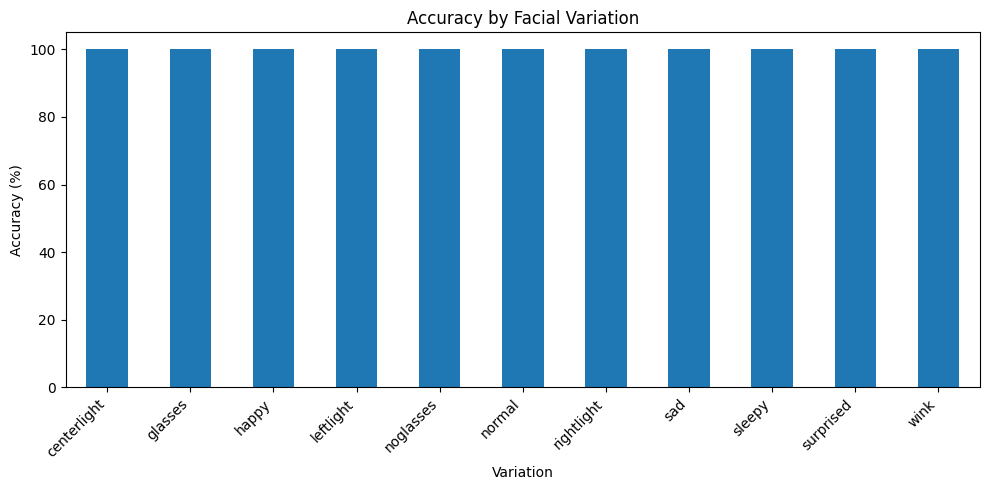

In [7]:
#confusion matrix and classification report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

cm = confusion_matrix(y, oof_pred, labels=selected_identities)
ConfusionMatrixDisplay(cm, display_labels=selected_identities).plot(cmap="Blues", xticks_rotation=45)
plt.title("ArcFace + SVM — 3-fold OOF Confusion Matrix")
plt.tight_layout(); plt.show()

print(classification_report(y, oof_pred, labels=selected_identities, digits=4, zero_division=0))
print(f"OOF accuracy: {accuracy_score(y, oof_pred):.4f}")

# Accuracy by facial variation
variation_results = pd.DataFrame({"Variation": variations, "Correct": y == oof_pred})
variation_results = variation_results.groupby("Variation").Correct.agg(["count", "sum", "mean"]).reset_index()
variation_results.columns = ["Variation", "Images", "Correct", "Accuracy"]
variation_results["Accuracy"] *= 100
print(variation_results.to_string(index=False))
variation_results.plot.bar(x="Variation", y="Accuracy", ylim=(0, 105), legend=False, figsize=(10, 5))
plt.ylabel("Accuracy (%)"); plt.title("Accuracy by Facial Variation"); plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.show()

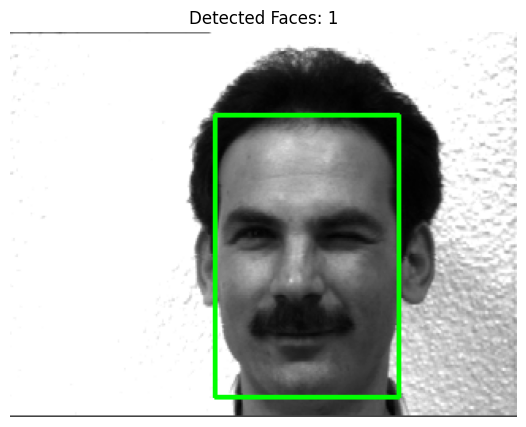

Faces detected: 1


In [8]:
# Visualize face detection 

sample = project_df.sample(1, random_state=60).iloc[0]

image = cv2.imread(sample["image_path"])
faces = app.get(image)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Draw detected bounding boxes
for face in faces:
    x1, y1, x2, y2 = face.bbox.astype(int)

    cv2.rectangle(
        image_rgb,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        2
    )

plt.figure(figsize=(7, 5))
plt.imshow(image_rgb)
plt.title(f"Detected Faces: {len(faces)}")
plt.axis("off")
plt.show()

print("Faces detected:", len(faces))

In [9]:
# Save key results to Kaggle output
OUTPUT_DIR = "/kaggle/working/arcface_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

fold_results_df.to_csv(f"{OUTPUT_DIR}/fold_results.csv", index=False)
variation_results.to_csv(f"{OUTPUT_DIR}/variation_analysis.csv", index=False)
pd.DataFrame(cm, index=selected_identities, columns=selected_identities).to_csv(f"{OUTPUT_DIR}/confusion_matrix.csv")
pd.DataFrame(classification_report(y, oof_pred, labels=selected_identities, output_dict=True, zero_division=0)).T.to_csv(f"{OUTPUT_DIR}/classification_report.csv")
pd.DataFrame({"Image": image_names, "True": y, "Variation": variations, "Predicted": oof_pred, "Correct": y == oof_pred}).to_csv(f"{OUTPUT_DIR}/predictions.csv", index=False)
print("Saved:", os.listdir(OUTPUT_DIR))

Saved: ['classification_report.csv', 'confusion_matrix.csv', 'predictions.csv', 'variation_analysis.csv', 'fold_results.csv']
